| Key              | Value                                                                                                                                                                                                                                                                                                            |
|:-----------------|:-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| **Week05** | Classification                                                                                                                                                                                                                                                                                           |
| **Course Names** | Machine Learning and Data Science.                                                                                                                                                                                               |
| **Submission Deadline**     | October 21, 2026, 11:45 PM                                                                                                                                                                                                                                                                                          |
| **Student Name & Number**     | Edward Chisaka - 1774058                                                                                                                                                                                                                                                                                                    |
| **Contact**      | edward.chisaka@stud.hslu.ch                                                                                                                                                                                                                                                                                           |
| **Note**         | The link directs to the specific GitHub file for this _Week05_ Lab implementation exercise.<br/> **_Titanic –_**.<br/> _Machine Learning from Disaster competition_. <br/> GitHub citation: [BibTeX](https://github.com/CH-CHISAKA/Machine_Learning_and_Data_Science/tree/main/04-assignments/04-assignment) |

# Import required libraries

In [1]:

# Cell 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    VotingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Libraries imported successfully.")

Libraries imported successfully.



# Load the competition datasets

In [3]:
train_path = Path("data/titanic/train.csv")
test_path = Path("data/titanic/test.csv")

train_df=pd.read_csv(train_path)
test_df=pd.read_csv(train_path)

display(train_df.head())

display(test_df.tail())

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


# EDA - Exploratory Data Analysis

In [4]:
print("Column name:")
print(train_df.columns.tolist())

Column name:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [5]:
print("Data Types and Null Values:")
train_df.info()

Data Types and Null Values:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [6]:
print("\n First five rows:")
display(train_df.head(5))

print("\n Last five rows:")
display(train_df.tail(5))


 First five rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



 Last five rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [7]:
print("Statistical Summary:")
# display(train_df.describe(include="all").T)
display(train_df.describe())

Statistical Summary:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
print("Missing values in training data:")
print(train_df.isnull().sum().sort_values(ascending=True))

Missing values in training data:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Embarked         2
Age            177
Cabin          687
dtype: int64


In [9]:
print("Missing values in test data:")
print(test_df.isnull().sum().sort_values(ascending=False))

Missing values in test data:
Cabin          687
Age            177
Embarked         2
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
SibSp            0
Parch            0
Ticket           0
Fare             0
dtype: int64


In [10]:
print("Duplicate training rows:", train_df.duplicated().sum())

Duplicate training rows: 0


In [11]:
print("Survival count:")
print(train_df["Survived"].value_counts())

Survival count:
Survived
0    549
1    342
Name: count, dtype: int64


In [12]:
print("\nSurvival proportions:")
print(train_df["Survived"].value_counts(normalize=True).round(3))


Survival proportions:
Survived
0    0.616
1    0.384
Name: proportion, dtype: float64


Text(0.5, 0, 'Passenger Class')

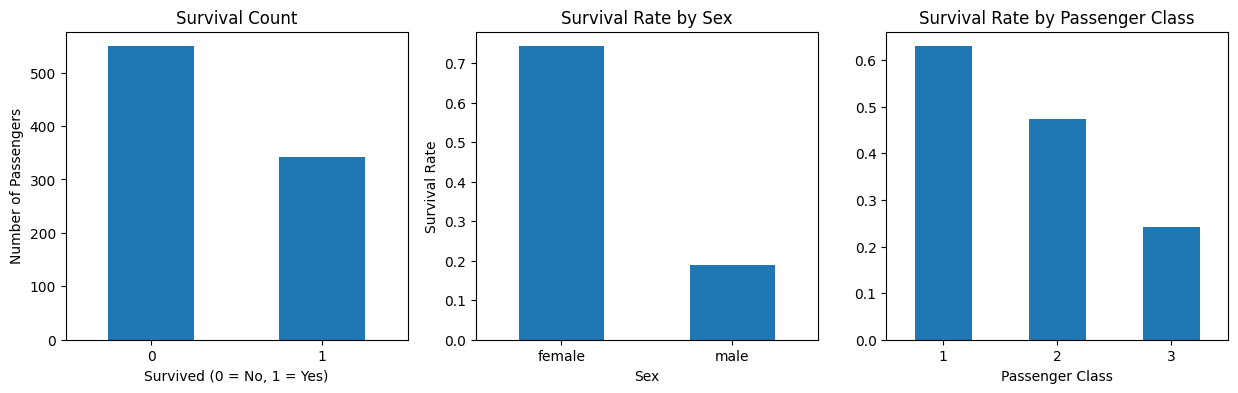

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

train_df["Survived"].value_counts().sort_index().plot(
    kind="bar", ax=axes[0], rot=0
)
axes[0].set_title("Survival Count")
axes[0].set_xlabel("Survived (0 = No, 1 = Yes)")
axes[0].set_ylabel("Number of Passengers")

survival_by_sex = train_df.groupby("Sex")["Survived"].mean()
survival_by_sex.plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title("Survival Rate by Sex")
axes[1].set_ylabel("Survival Rate")

survival_by_class = train_df.groupby("Pclass")["Survived"].mean()
survival_by_class.plot(kind="bar", ax=axes[2], rot=0)
axes[2].set_title("Survival Rate by Passenger Class")
axes[2].set_xlabel("Passenger Class")

# Feature engineering

In [34]:
def create_features(data):
    data = data.copy()

    # Extract titles from passenger names.
    data["Title"] = (
        data["Name"]
        .str.extract(r",\s*([^.]*)\.", expand=False)
        .str.strip()
    )

    # Combine uncommon titles into a smaller group.
    title_counts = data["Title"].value_counts()
    common_titles = ["Mr", "Mrs", "Miss", "Master"]

    data["Title"] = data["Title"].where(
        data["Title"].isin(common_titles),
        "Rare"
    )

    data["FamilySize"] = (
        data["SibSp"] + data["Parch"] + 1
    )

    data["IsAlone"] = (
        data["FamilySize"] == 1
    ).astype(int)

    # Preserve cabin availability as a separate signal.
    data["HasCabin"] = data["Cabin"].notna().astype(int)

    data["Deck"] = (
        data["Cabin"]
        .str[0]
        .fillna("Unknown")
    )

    # Remove original columns transformed
    data = data.drop(
        columns=[
            "PassengerId",
            "Name",
            "Ticket",
            "Cabin"
        ]
    )

    return data


X = create_features(train_df.drop(columns=["Survived"]))
y = train_df["Survived"].copy()

X_test = create_features(test_df)

print("Engineered training features:")
display(X.head())

print("\nTraining features shape:", X.shape)
print("Test features shape:", X_test.shape)

Engineered training features:


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,FamilySize,IsAlone,HasCabin,Deck
0,3,male,22.0,1,0,7.2500,S,Mr,2,0,0,Unknown
1,1,female,38.0,1,0,71.2833,C,Mrs,2,0,1,C
2,3,female,26.0,0,0,7.9250,S,Miss,1,1,0,Unknown
3,1,female,35.0,1,0,53.1000,S,Mrs,2,0,1,C
4,3,male,35.0,0,0,8.0500,S,Mr,1,1,0,Unknown



Training features shape: (891, 12)
Test features shape: (891, 13)


**Summary**

Title: a passenger's title, such as Mr, Mrs, Miss or Master.

FamilySize: the passenger plus siblings/spouses and parents/children.

IsAlone: whether the passenger travelled alone according to family counts.

HasCabin: whether cabin information is available.

Deck: the first letter of the cabin identifier, with missing entries represented as unknown.

# Preprocessing 

In [35]:
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=["number"]
).columns.tolist()

numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ]
)

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Preprocessing pipeline is ready.")

Numeric features: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone', 'HasCabin']
Categorical features: ['Sex', 'Embarked', 'Title', 'Deck']
Preprocessing pipeline is ready.


# Split the training data

In [36]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Validation rows:", X_valid.shape[0])

print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).round(3))

print("\nValidation target proportions:")
print(y_valid.value_counts(normalize=True).round(3))


Training rows: 712
Validation rows: 179

Training target proportions:
Survived
0    0.617
1    0.383
Name: proportion, dtype: float64

Validation target proportions:
Survived
0    0.615
1    0.385
Name: proportion, dtype: float64


# Logistic regression model

Logistic Regression Accuracy: 0.8436

Classification report:
              precision    recall  f1-score   support

           0       0.85      0.90      0.88       110
           1       0.83      0.75      0.79        69

    accuracy                           0.84       179
   macro avg       0.84      0.83      0.83       179
weighted avg       0.84      0.84      0.84       179



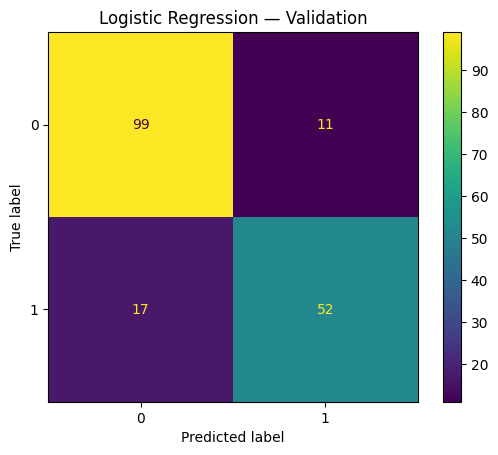

In [37]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=2000,
                random_state=42
            )
        )
    ]
)

logistic_model.fit(X_train, y_train)

logistic_predictions = logistic_model.predict(X_valid)

logistic_accuracy = accuracy_score(
    y_valid,
    logistic_predictions
)

print(f"Logistic Regression Accuracy: {logistic_accuracy:.4f}")

print("\nClassification report:")
print(
    classification_report(
        y_valid,
        logistic_predictions,
        zero_division=0
    )
)

ConfusionMatrixDisplay.from_predictions(
    y_valid,
    logistic_predictions
)
plt.title("Logistic Regression — Validation")
plt.show()
